## 1. Persiapan


### 1.1 Import Library

In [35]:
import os
import io
import heapq
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import dctn, idctn
from skimage import data
from skimage.metrics import structural_similarity
from IPython.display import display

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 10
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

os.makedirs("output", exist_ok=True)   # folder untuk menyimpan hasil
print("Library siap digunakan.")

Library siap digunakan.


### 1.2 Memuat Citra
program memakai citra contoh dari `scikit-image`. Citra yang sangat besar diperkecil ke `MAX_SIZE` agar proses tetap cepat.

Citra dimuat dari : images/sample.jpg
Dimensi          : 288 x 512 piksel
Ukuran mentah    : 432.0 KB (24 bit/piksel)


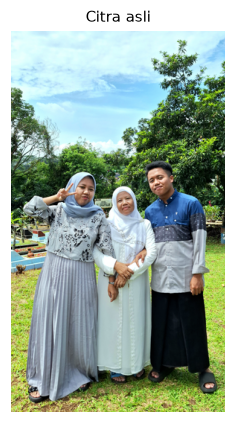

In [36]:
IMAGE_PATH = "images/sample.jpg"          # <- sumber citra
MAX_SIZE = 512                     # sisi terpanjang maksimum (None = tanpa resize/ukuran asli)

if os.path.exists(IMAGE_PATH):
    pil_img = Image.open(IMAGE_PATH).convert("RGB")
    print("Citra dimuat dari :", IMAGE_PATH)
else:
    pil_img = Image.fromarray(data.astronaut())
    print("File tidak ditemukan, memakai citra contoh dari scikit-image.")

if MAX_SIZE and max(pil_img.size) > MAX_SIZE:
    pil_img.thumbnail((MAX_SIZE, MAX_SIZE), Image.LANCZOS)

img = np.array(pil_img)                  # array uint8 (H, W, 3)
H, W, _ = img.shape
ORIGINAL_BITS = H * W * 3 * 8            # ukuran citra mentah (24 bit/piksel)

print(f"Dimensi          : {W} x {H} piksel")
print(f"Ukuran mentah    : {ORIGINAL_BITS / 8 / 1024:.1f} KB (24 bit/piksel)")

plt.figure(figsize=(4.5, 4.5))
plt.imshow(img)
plt.title("Citra asli")
plt.axis("off")
plt.show()

### 1.3 Fungsi Metrik Evaluasi

In [37]:
def mse(a, b):
    """Mean Squared Error antara dua citra."""
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)


def psnr(a, b):
    """Peak Signal-to-Noise Ratio (dB) untuk citra 8 bit."""
    m = mse(a, b)
    return float("inf") if m == 0 else 10 * np.log10(255.0 ** 2 / m)


def ssim_rgb(a, b):
    """Structural Similarity Index untuk citra RGB."""
    return structural_similarity(a, b, channel_axis=2, data_range=255)

### 1.4 Tabel Kuantisasi dan Konversi Ruang Warna
Tabel kuantisasi di bawah adalah tabel standar JPEG (Annex K). Parameter `quality` (1 sampai 100) menskalakan tabel tersebut: **semakin kecil quality, semakin besar pembagi, semakin banyak koefisien menjadi nol**.

In [38]:
# Tabel kuantisasi standar JPEG
Q_LUM = np.array([
    [16, 11, 10, 16,  24,  40,  51,  61],
    [12, 12, 14, 19,  26,  58,  60,  55],
    [14, 13, 16, 24,  40,  57,  69,  56],
    [14, 17, 22, 29,  51,  87,  80,  62],
    [18, 22, 37, 56,  68, 109, 103,  77],
    [24, 35, 55, 64,  81, 104, 113,  92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103,  99]], dtype=np.float64)

Q_CHR = np.full((8, 8), 99, dtype=np.float64)
Q_CHR[:4, :4] = [[17, 18, 24, 47],
                 [18, 21, 26, 66],
                 [24, 26, 56, 99],
                 [47, 66, 99, 99]]


def scale_qtable(Q, quality):
    """Skalakan tabel kuantisasi sesuai faktor quality (1-100), cara standar IJG."""
    quality = int(np.clip(quality, 1, 100))
    s = 5000 / quality if quality < 50 else 200 - 2 * quality
    return np.clip(np.floor((Q * s + 50) / 100), 1, 255)


def rgb_to_ycbcr(rgb):
    rgb = rgb.astype(np.float64)
    R, G, B = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    Y  =       0.299    * R + 0.587    * G + 0.114    * B
    Cb = 128 - 0.168736 * R - 0.331264 * G + 0.5      * B
    Cr = 128 + 0.5      * R - 0.418688 * G - 0.081312 * B
    return np.stack([Y, Cb, Cr], axis=-1)


def ycbcr_to_rgb(ycc):
    Y, Cb, Cr = ycc[..., 0], ycc[..., 1] - 128, ycc[..., 2] - 128
    R = Y + 1.402    * Cr
    G = Y - 0.344136 * Cb - 0.714136 * Cr
    B = Y + 1.772    * Cb
    return np.stack([R, G, B], axis=-1)


def downsample2(ch):
    """Chroma subsampling 4:2:0, rata-rata setiap blok 2x2."""
    h, w = ch.shape
    ch = np.pad(ch, ((0, h % 2), (0, w % 2)), mode="edge")
    return ch.reshape(ch.shape[0] // 2, 2, ch.shape[1] // 2, 2).mean(axis=(1, 3))


def upsample2(ch, shape):
    """Kembalikan ukuran channel (replikasi piksel), lalu potong sesuai ukuran asli."""
    up = np.repeat(np.repeat(ch, 2, axis=0), 2, axis=1)
    return up[:shape[0], :shape[1]]


print("Tabel kuantisasi luminansi, quality=50 (sama dengan tabel standar):")
print(scale_qtable(Q_LUM, 50).astype(int))
print("\nTabel kuantisasi luminansi, quality=10 (pembagi jauh lebih besar):")
print(scale_qtable(Q_LUM, 10).astype(int))

Tabel kuantisasi luminansi, quality=50 (sama dengan tabel standar):
[[ 16  11  10  16  24  40  51  61]
 [ 12  12  14  19  26  58  60  55]
 [ 14  13  16  24  40  57  69  56]
 [ 14  17  22  29  51  87  80  62]
 [ 18  22  37  56  68 109 103  77]
 [ 24  35  55  64  81 104 113  92]
 [ 49  64  78  87 103 121 120 101]
 [ 72  92  95  98 112 100 103  99]]

Tabel kuantisasi luminansi, quality=10 (pembagi jauh lebih besar):
[[ 80  55  50  80 120 200 255 255]
 [ 60  60  70  95 130 255 255 255]
 [ 70  65  80 120 200 255 255 255]
 [ 70  85 110 145 255 255 255 255]
 [ 90 110 185 255 255 255 255 255]
 [120 175 255 255 255 255 255 255]
 [245 255 255 255 255 255 255 255]
 [255 255 255 255 255 255 255 255]]


### Transformasi DCT per Blok 8x8
Satu channel dipecah menjadi blok 8x8, diberi *level shift* (dikurangi 128), ditransformasi dengan DCT 2D, lalu dikuantisasi. Proses kebalikannya dipakai untuk rekonstruksi.

In [39]:
BLOCK = 8


def pad_to_block(ch):
    """Tambah tepi agar tinggi dan lebar kelipatan 8."""
    h, w = ch.shape
    return np.pad(ch, ((0, (-h) % BLOCK), (0, (-w) % BLOCK)), mode="edge")


def to_blocks(ch):
    """(H, W) -> (H/8, W/8, 8, 8)"""
    h, w = ch.shape
    return ch.reshape(h // BLOCK, BLOCK, w // BLOCK, BLOCK).swapaxes(1, 2)


def from_blocks(blocks):
    """(H/8, W/8, 8, 8) -> (H, W)"""
    nh, nw = blocks.shape[:2]
    return blocks.swapaxes(1, 2).reshape(nh * BLOCK, nw * BLOCK)


def compress_channel(ch, Q):
    """Level shift -> blok 8x8 -> DCT 2D -> kuantisasi. Hasil: koefisien integer."""
    blocks = to_blocks(pad_to_block(ch.astype(np.float64)) - 128)
    coef = dctn(blocks, axes=(2, 3), norm="ortho")
    return np.round(coef / Q).astype(np.int32)


def decompress_channel(q, Q, shape):
    """De-kuantisasi -> IDCT 2D -> gabung blok -> level shift balik -> potong tepi."""
    blocks = idctn(q * Q, axes=(2, 3), norm="ortho")
    return (from_blocks(blocks) + 128)[:shape[0], :shape[1]]

### Estimasi Ukuran Bitstream (Zig-zag, RLE, Huffman)
Agar ukuran hasil kompresi benar-benar dihitung (bukan sekadar perkiraan), koefisien terkuantisasi diproses seperti pada JPEG:

1. **Zig-zag scan**: koefisien diurutkan dari frekuensi rendah ke tinggi sehingga nol-nol berkumpul di ujung.
2. **DC**: selisih (DPCM) terhadap blok sebelumnya, dikodekan sebagai *kategori* (jumlah bit nilai) ditambah bit nilai itu sendiri.
3. **AC**: dikodekan sebagai simbol `(run, size)`, yaitu jumlah nol sebelumnya dan jumlah bit nilai. `(0,0)` berarti *End of Block* (EOB) dan `(15,0)` berarti 16 nol berturut-turut (ZRL).
4. **Huffman**: panjang total kode dihitung dari frekuensi simbol (kode optimal), ditambah bit nilai koefisien.

> Catatan: ukuran yang dilaporkan adalah ukuran *payload* (data citra) tanpa header dan tabel Huffman, sehingga sedikit lebih kecil dibanding file `.jpg` asli.

In [40]:
def zigzag_order(n=8):
    """Urutan indeks zig-zag untuk blok n x n."""
    idx = sorted(((i, j) for i in range(n) for j in range(n)),
                 key=lambda p: (p[0] + p[1], p[1] if (p[0] + p[1]) % 2 == 0 else p[0]))
    return np.array([p[0] for p in idx]), np.array([p[1] for p in idx])

ZZ_I, ZZ_J = zigzag_order()


def category(v):
    """Jumlah bit untuk merepresentasikan |v| (kategori JPEG)."""
    return int(abs(int(v))).bit_length()


def huffman_total_bits(symbols):
    """Total panjang bit hasil kode Huffman optimal untuk deretan simbol.
    Total bit = jumlah bobot semua simpul internal pohon Huffman."""
    freq = Counter(symbols)
    if len(freq) <= 1:
        return len(symbols)          # satu simbol saja: 1 bit per simbol
    heap = list(freq.values())
    heapq.heapify(heap)
    total = 0
    while len(heap) > 1:
        s = heapq.heappop(heap) + heapq.heappop(heap)
        total += s
        heapq.heappush(heap, s)
    return total


def estimate_bits(q):
    """Estimasi jumlah bit satu channel terkuantisasi q (nh, nw, 8, 8)."""
    zz = q.reshape(-1, BLOCK, BLOCK)[:, ZZ_I, ZZ_J]       # (jumlah_blok, 64) urutan zig-zag

    # --- DC: DPCM antarblok ---
    dc_diff = np.diff(zz[:, 0], prepend=0)
    dc_syms = [category(d) for d in dc_diff]
    extra_bits = sum(dc_syms)

    # --- AC: simbol (run, size) ---
    ac_syms = []
    for blk in zz[:, 1:]:
        nz = np.nonzero(blk)[0]
        if len(nz) == 0:
            ac_syms.append((0, 0))                         # EOB
            continue
        run = 0
        for k in range(nz[-1] + 1):
            v = int(blk[k])
            if v == 0:
                run += 1
            else:
                while run > 15:
                    ac_syms.append((15, 0))                # ZRL
                    run -= 16
                s = category(v)
                ac_syms.append((run, s))
                extra_bits += s
                run = 0
        if nz[-1] < 62:
            ac_syms.append((0, 0))                         # EOB

    return huffman_total_bits(dc_syms) + huffman_total_bits(ac_syms) + extra_bits

### Fungsi Kompresi dan Dekompresi Citra Berwarna
Seluruh tahap digabung dalam satu fungsi. Fungsi ini mengembalikan citra hasil rekonstruksi, jumlah bit terkompresi, dan koefisien terkuantisasi.

In [41]:
def dct_compress_rgb(img, quality, subsample=True):
    """Kompresi + dekompresi citra RGB dengan pipeline DCT ala JPEG baseline."""
    Ql, Qc = scale_qtable(Q_LUM, quality), scale_qtable(Q_CHR, quality)

    # 1) RGB -> YCbCr, 2) chroma subsampling 4:2:0
    Y, Cb, Cr = np.moveaxis(rgb_to_ycbcr(img), -1, 0)
    Cb_s, Cr_s = (downsample2(Cb), downsample2(Cr)) if subsample else (Cb, Cr)

    # 3) blok 8x8 -> DCT -> kuantisasi
    qY, qCb, qCr = compress_channel(Y, Ql), compress_channel(Cb_s, Qc), compress_channel(Cr_s, Qc)

    # 4) hitung ukuran bitstream
    bits = estimate_bits(qY) + estimate_bits(qCb) + estimate_bits(qCr)

    # --- dekompresi ---
    Yr  = decompress_channel(qY,  Ql, Y.shape)
    Cbr = decompress_channel(qCb, Qc, Cb_s.shape)
    Crr = decompress_channel(qCr, Qc, Cr_s.shape)
    if subsample:
        Cbr, Crr = upsample2(Cbr, Y.shape), upsample2(Crr, Y.shape)

    recon = np.clip(np.round(ycbcr_to_rgb(np.stack([Yr, Cbr, Crr], axis=-1))), 0, 255).astype(np.uint8)
    return {"recon": recon, "bits": bits, "qcoefs": (qY, qCb, qCr)}

## 4. Percobaan dan Analisis

### 4.1 Memahami DCT pada Satu Blok 8x8
Berikut satu blok piksel dari channel luminansi (Y), hasil DCT-nya, hasil kuantisasi (quality = 50), dan hasil rekonstruksinya. Perhatikan bahwa **energi menumpuk di pojok kiri atas (frekuensi rendah)** dan **sebagian besar koefisien lain menjadi 0 setelah kuantisasi**.

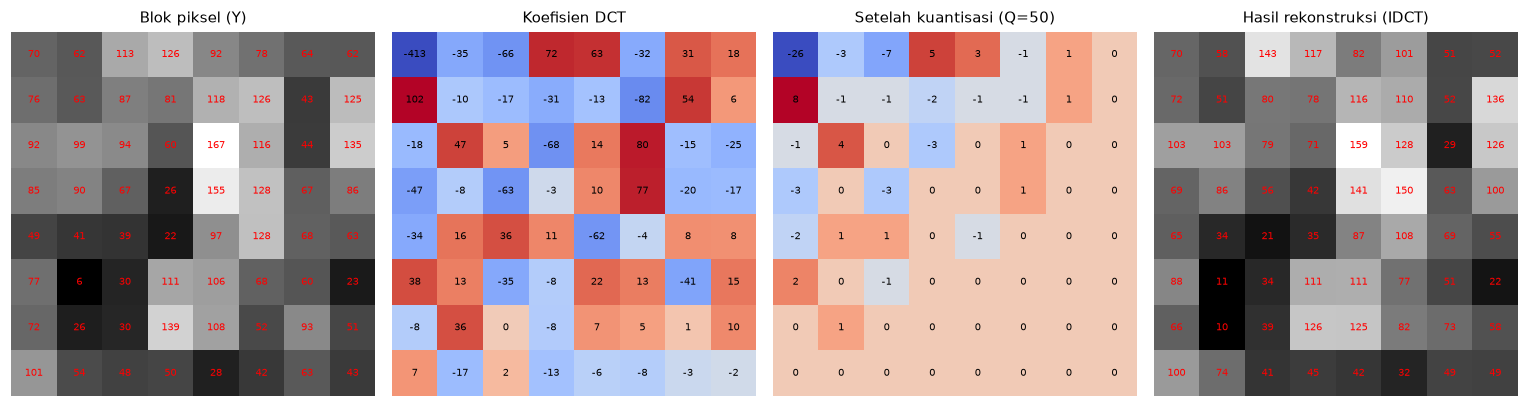

Koefisien tidak nol sebelum kuantisasi : 63 / 64
Koefisien tidak nol setelah kuantisasi : 28 / 64
Galat rata-rata piksel pada blok ini    : 10.53


In [42]:
Y_full = rgb_to_ycbcr(img)[..., 0]
by, bx = 164, 192                                   # koordinat blok yang diamati (memuat tepi wajah)
blok = Y_full[by:by + BLOCK, bx:bx + BLOCK]
Q50 = scale_qtable(Q_LUM, 50)

dct_blok = dctn(blok - 128, norm="ortho")
q_blok   = np.round(dct_blok / Q50)
rec_blok = idctn(q_blok * Q50, norm="ortho") + 128


def show_matrix(ax, m, title, cmap, color, log=False):
    """Tampilkan matriks 8x8 beserta nilainya. log=True memakai skala warna log agar koefisien kecil tetap terlihat."""
    shown = np.sign(m) * np.log1p(np.abs(m)) if log else m
    ax.imshow(shown, cmap=cmap)
    for (i, j), val in np.ndenumerate(m):
        ax.text(j, i, f"{np.round(val) + 0.0:.0f}", ha="center", va="center", fontsize=6.5, color=color)
    ax.set_title(title)
    ax.axis("off")


fig, axes = plt.subplots(1, 4, figsize=(14, 3.9))
show_matrix(axes[0], blok,     "Blok piksel (Y)",           "gray",     "red")
show_matrix(axes[1], dct_blok, "Koefisien DCT",             "coolwarm", "black", log=True)
show_matrix(axes[2], q_blok,   "Setelah kuantisasi (Q=50)", "coolwarm", "black", log=True)
show_matrix(axes[3], rec_blok, "Hasil rekonstruksi (IDCT)", "gray",     "red")
plt.tight_layout()
plt.show()

print(f"Koefisien tidak nol sebelum kuantisasi : {np.count_nonzero(np.round(dct_blok))} / 64")
print(f"Koefisien tidak nol setelah kuantisasi : {int(np.count_nonzero(q_blok))} / 64")
print(f"Galat rata-rata piksel pada blok ini    : {np.abs(blok - rec_blok).mean():.2f}")

**64 fungsi basis DCT 8x8.** Setiap blok citra dapat dinyatakan sebagai kombinasi linear dari 64 pola ini. Pola di kiri atas mewakili perubahan halus (frekuensi rendah), pola di kanan bawah mewakili detail halus (frekuensi tinggi) yang paling banyak dibuang saat kuantisasi.

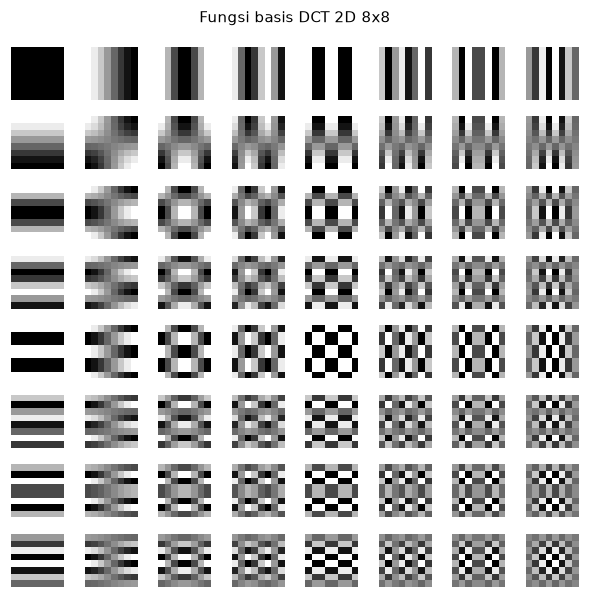

In [43]:
fig, axes = plt.subplots(8, 8, figsize=(5.5, 5.5))
for u in range(8):
    for v in range(8):
        c = np.zeros((8, 8))
        c[u, v] = 1
        axes[u, v].imshow(idctn(c, norm="ortho"), cmap="gray")
        axes[u, v].axis("off")
plt.suptitle("Fungsi basis DCT 2D 8x8", fontsize=10)
plt.tight_layout()
plt.show()

### 4.2 Kompresi pada Berbagai Nilai Quality
Citra dikompresi dengan `quality` = 5, 10, 25, 50, 75, dan 90, lalu dihitung seluruh metrik evaluasinya.

In [44]:
QUALITIES = [5, 10, 25, 50, 75, 90]

hasil, rows = {}, []
for q in QUALITIES:
    r = dct_compress_rgb(img, q)
    hasil[q] = r
    coefs = np.concatenate([c.ravel() for c in r["qcoefs"]])
    rows.append({
        "Quality"      : q,
        "Ukuran (KB)"  : r["bits"] / 8 / 1024,
        "CR"           : ORIGINAL_BITS / r["bits"],
        "bpp"          : r["bits"] / (H * W),
        "Hemat (%)"    : (1 - r["bits"] / ORIGINAL_BITS) * 100,
        "MSE"          : mse(img, r["recon"]),
        "PSNR (dB)"    : psnr(img, r["recon"]),
        "SSIM"         : ssim_rgb(img, r["recon"]),
        "Koef. nol (%)": np.mean(coefs == 0) * 100,
    })

df = pd.DataFrame(rows)
print(f"Ukuran citra mentah: {ORIGINAL_BITS / 8 / 1024:.1f} KB\n")
display(df.round(3))

Ukuran citra mentah: 432.0 KB



,Quality,Ukuran (KB),CR,bpp,Hemat (%),MSE,PSNR (dB),SSIM,Koef. nol (%)
0,5,4.052,106.617,0.225,99.062,586.063,20.451,0.639,96.804
1,10,7.623,56.671,0.423,98.235,361.153,22.554,0.749,94.081
2,25,15.499,27.873,0.861,96.412,217.206,24.762,0.846,88.723
3,50,24.772,17.439,1.376,94.266,141.666,26.618,0.896,82.949
4,75,37.620,11.483,2.090,91.292,87.418,28.715,0.932,75.188
5,90,60.505,7.140,3.361,85.994,44.611,31.636,0.963,62.214


In [50]:
print("| Quality | Ukuran (KB) | CR | bpp | PSNR (dB) | SSIM |")
print("|---:|---:|---:|---:|---:|---:|")
for _, r in df.iterrows():
    print(f"| {int(r['Quality'])} | {r['Ukuran (KB)']:.1f} | {r['CR']:.1f}x | {r['bpp']:.2f} | {r['PSNR (dB)']:.2f} | {r['SSIM']:.3f} |")

| Quality | Ukuran (KB) | CR | bpp | PSNR (dB) | SSIM |
|---:|---:|---:|---:|---:|---:|
| 5 | 4.1 | 106.6x | 0.23 | 20.45 | 0.639 |
| 10 | 7.6 | 56.7x | 0.42 | 22.55 | 0.749 |
| 25 | 15.5 | 27.9x | 0.86 | 24.76 | 0.846 |
| 50 | 24.8 | 17.4x | 1.38 | 26.62 | 0.896 |
| 75 | 37.6 | 11.5x | 2.09 | 28.71 | 0.932 |
| 90 | 60.5 | 7.1x | 3.36 | 31.64 | 0.963 |


### 4.3 Perbandingan Visual

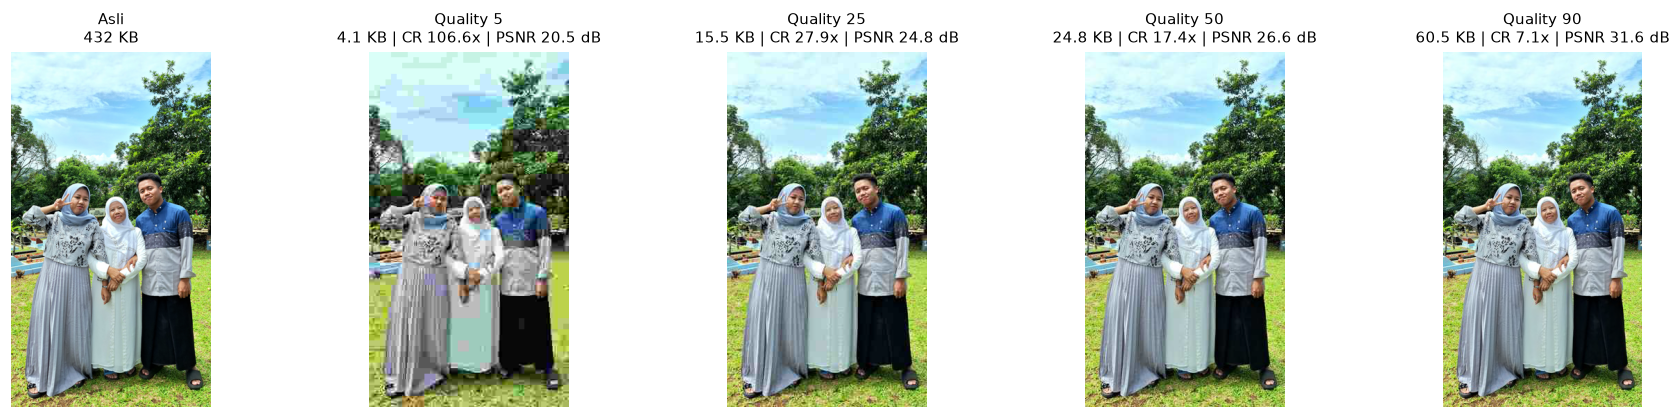

In [45]:
show_q = [5, 25, 50, 90]
fig, axes = plt.subplots(1, len(show_q) + 1, figsize=(17, 3.9))
axes[0].imshow(img)
axes[0].set_title(f"Asli\n{ORIGINAL_BITS / 8 / 1024:.0f} KB")
for ax, q in zip(axes[1:], show_q):
    row = df[df.Quality == q].iloc[0]
    ax.imshow(hasil[q]["recon"])
    ax.set_title(f"Quality {q}\n{row['Ukuran (KB)']:.1f} KB | CR {row['CR']:.1f}x | PSNR {row['PSNR (dB)']:.1f} dB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Zoom pada area detail dan peta galat.** Baris atas: potongan citra. Baris bawah: selisih absolut terhadap citra asli (semakin terang semakin besar galatnya). Pada quality rendah terlihat artefak khas JPEG berupa **efek blok (*blocking*)** dan **gangguan di sekitar tepi (*ringing*)**.

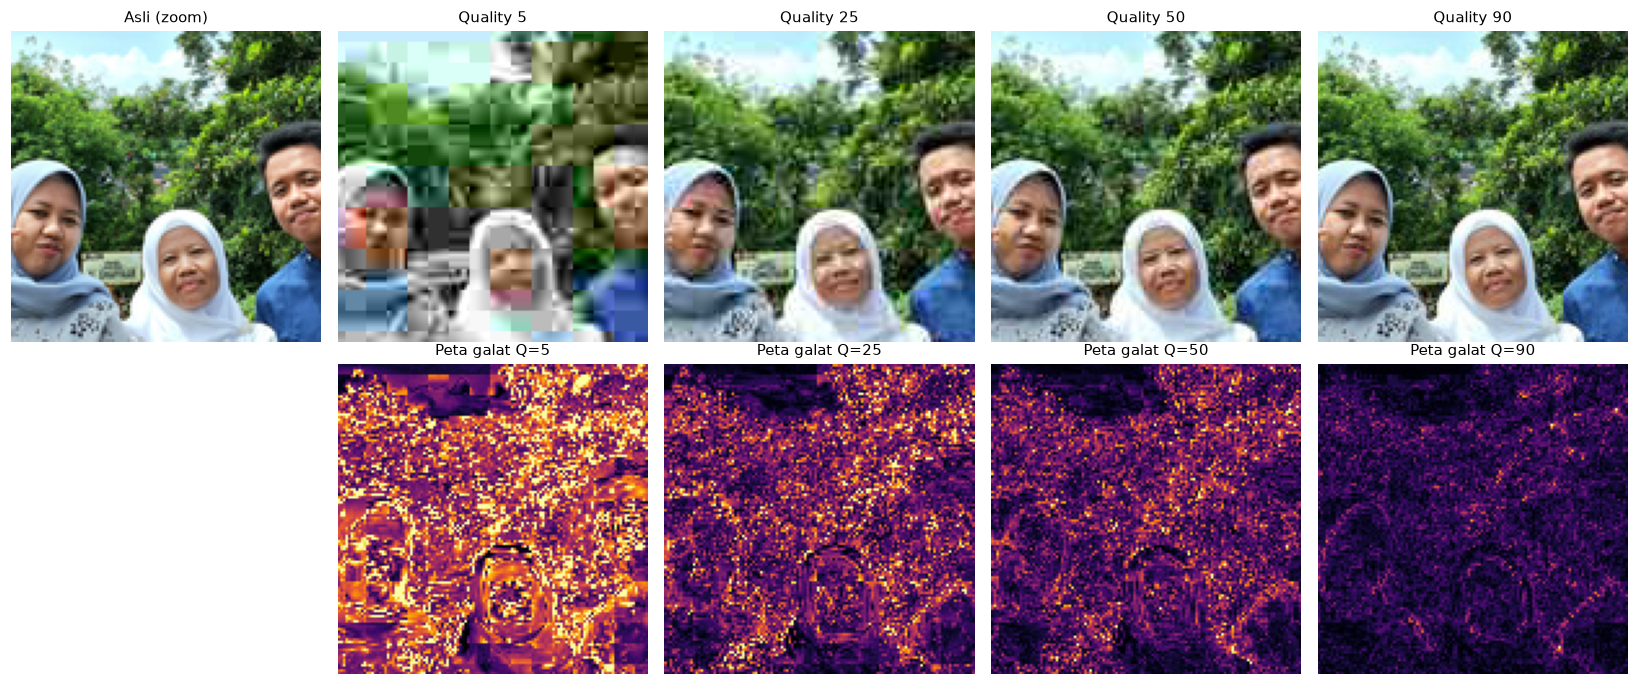

In [46]:
zy, zx, zs = 140, 85, 120          # posisi (baris, kolom) dan ukuran area zoom, silakan disesuaikan
zy, zx = min(zy, H - zs), min(zx, W - zs)
crop = (slice(zy, zy + zs), slice(zx, zx + zs))

fig, axes = plt.subplots(2, len(show_q) + 1, figsize=(15, 6.3))
axes[0, 0].imshow(img[crop]);  axes[0, 0].set_title("Asli (zoom)")
axes[1, 0].axis("off")
for k, q in enumerate(show_q, start=1):
    rec = hasil[q]["recon"]
    err = np.abs(img.astype(int) - rec.astype(int)).mean(axis=2)
    axes[0, k].imshow(rec[crop]);                         axes[0, k].set_title(f"Quality {q}")
    axes[1, k].imshow(err[crop], cmap="inferno", vmin=0, vmax=40)
    axes[1, k].set_title(f"Peta galat Q={q}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.4 Grafik Trade-off Ukuran vs Kualitas

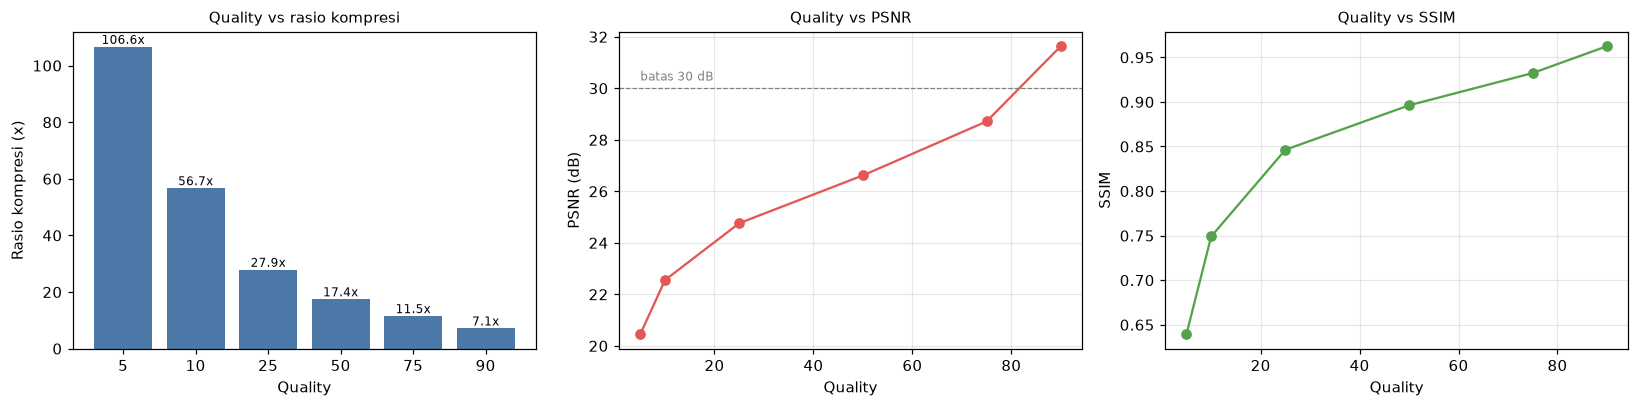

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].bar([str(q) for q in df.Quality], df["CR"], color="#4C78A8")
axes[0].set_xlabel("Quality"); axes[0].set_ylabel("Rasio kompresi (x)")
axes[0].set_title("Quality vs rasio kompresi")
for i, v in enumerate(df["CR"]):
    axes[0].text(i, v, f"{v:.1f}x", ha="center", va="bottom", fontsize=8)

axes[1].plot(df.Quality, df["PSNR (dB)"], "o-", color="#E45756")
axes[1].axhline(30, ls="--", color="gray", lw=0.8)
axes[1].text(df.Quality.iloc[0], 30.3, "batas 30 dB", fontsize=8, color="gray")
axes[1].set_xlabel("Quality"); axes[1].set_ylabel("PSNR (dB)")
axes[1].set_title("Quality vs PSNR")

axes[2].plot(df.Quality, df["SSIM"], "o-", color="#54A24B")
axes[2].set_xlabel("Quality"); axes[2].set_ylabel("SSIM")
axes[2].set_title("Quality vs SSIM")

for ax in axes[1:]:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.5 Perbandingan dengan JPEG Pillow dan PNG (Lossless)
Hasil implementasi sendiri dibandingkan dengan encoder JPEG milik Pillow (`optimize=True`, subsampling 4:2:0, supaya setara) dan dengan PNG sebagai pembanding kompresi *lossless*.

PNG (lossless)   :   291.8 KB | CR = 1.48x | PSNR = inf (identik)
Mentah (raw)     :   432.0 KB | CR = 1.00x



,Quality,Ukuran DCT (KB),Ukuran Pillow (KB),PSNR DCT,PSNR Pillow,SSIM DCT,SSIM Pillow
0,5,4.052,4.438,20.451,20.527,0.639,0.643
1,10,7.623,8.032,22.554,22.644,0.749,0.753
2,25,15.499,15.970,24.762,24.882,0.846,0.850
3,50,24.772,25.312,26.618,26.779,0.896,0.900
4,75,37.620,38.288,28.715,29.011,0.932,0.936
5,90,60.505,61.443,31.636,32.249,0.963,0.966


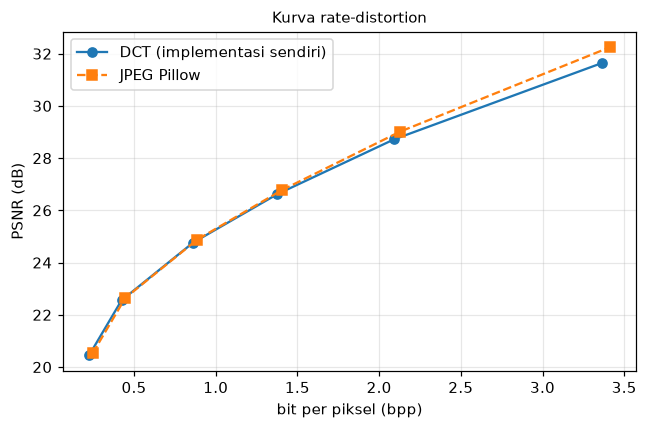

In [48]:
def pillow_jpeg(img, quality):
    """Kompres dengan encoder JPEG Pillow, kembalikan (citra rekonstruksi, ukuran dalam bit)."""
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="JPEG", quality=quality, subsampling=2, optimize=True)
    size_bits = buf.tell() * 8
    buf.seek(0)
    return np.array(Image.open(buf).convert("RGB")), size_bits


# Pembanding lossless
buf = io.BytesIO()
Image.fromarray(img).save(buf, format="PNG", optimize=True)
png_bits = buf.tell() * 8
print(f"PNG (lossless)   : {png_bits / 8 / 1024:7.1f} KB | CR = {ORIGINAL_BITS / png_bits:.2f}x | PSNR = inf (identik)")
print(f"Mentah (raw)     : {ORIGINAL_BITS / 8 / 1024:7.1f} KB | CR = 1.00x\n")

rows_cmp, pil_results = [], {}
for q in QUALITIES:
    rec_p, bits_p = pillow_jpeg(img, q)
    pil_results[q] = rec_p
    d = df[df.Quality == q].iloc[0]
    rows_cmp.append({
        "Quality"          : q,
        "Ukuran DCT (KB)"  : d["Ukuran (KB)"],
        "Ukuran Pillow (KB)": bits_p / 8 / 1024,
        "PSNR DCT"         : d["PSNR (dB)"],
        "PSNR Pillow"      : psnr(img, rec_p),
        "SSIM DCT"         : d["SSIM"],
        "SSIM Pillow"      : ssim_rgb(img, rec_p),
    })

df_cmp = pd.DataFrame(rows_cmp)
display(df_cmp.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(df["bpp"], df["PSNR (dB)"], "o-", label="DCT (implementasi sendiri)")
ax.plot(df_cmp["Ukuran Pillow (KB)"] * 8 * 1024 / (H * W), df_cmp["PSNR Pillow"], "s--", label="JPEG Pillow")
ax.set_xlabel("bit per piksel (bpp)")
ax.set_ylabel("PSNR (dB)")
ax.set_title("Kurva rate-distortion")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### 4.6 Menyimpan Hasil
Hasil rekonstruksi, file JPEG dari Pillow, dan tabel evaluasi disimpan di folder `output/`.

In [49]:
for q in QUALITIES:
    Image.fromarray(hasil[q]["recon"]).save(f"output/rekonstruksi_dct_q{q}.png")
    Image.fromarray(img).save(f"output/pillow_q{q}.jpg", quality=q, subsampling=2, optimize=True)

df.round(4).to_csv("output/hasil_kompresi.csv", index=False)
df_cmp.round(4).to_csv("output/perbandingan_pillow.csv", index=False)

print("File tersimpan di folder output/ :")
for f in sorted(os.listdir("output")):
    print(f"  - {f:32s} {os.path.getsize(os.path.join('output', f)) / 1024:8.1f} KB")

File tersimpan di folder output/ :
  - hasil_kompresi.csv                    0.5 KB
  - perbandingan_pillow.csv               0.4 KB
  - pillow_q10.jpg                        8.0 KB
  - pillow_q25.jpg                       16.0 KB
  - pillow_q5.jpg                         4.4 KB
  - pillow_q50.jpg                       25.3 KB
  - pillow_q75.jpg                       38.3 KB
  - pillow_q90.jpg                       61.4 KB
  - rekonstruksi_dct_q10.png            178.7 KB
  - rekonstruksi_dct_q25.png            231.3 KB
  - rekonstruksi_dct_q5.png             111.1 KB
  - rekonstruksi_dct_q50.png            263.1 KB
  - rekonstruksi_dct_q75.png            280.5 KB
  - rekonstruksi_dct_q90.png            286.6 KB


## 5. Kesimpulan
Berdasarkan percobaan pada citra berukuran 512 x 512 piksel (ukuran mentah 768 KB), diperoleh kesimpulan sebagai berikut:

1. **Kompresi berbasis DCT sangat efektif.** Pada *quality* 50, ukuran citra turun dari 768 KB menjadi sekitar **25,9 KB** (rasio kompresi **29,7x**, hemat 96,6%) dengan **PSNR 31,76 dB** dan **SSIM 0,916**. Sebagai pembanding, kompresi *lossless* PNG hanya mencapai sekitar 412,5 KB (1,86x).
2. **Penyebab utama efisiensi adalah kuantisasi.** Pada *quality* 50, sekitar **90,6%** koefisien DCT menjadi nol, sehingga mudah dipadatkan oleh zig-zag, RLE, dan Huffman. Pengamatan satu blok 8x8 juga menunjukkan hanya 11 dari 64 koefisien yang bertahan, namun blok tetap dapat direkonstruksi dengan baik.
3. **Ada *trade-off* antara ukuran dan kualitas.** Menaikkan *quality* dari 5 menjadi 25 menambah ukuran hanya sekitar 11,5 KB tetapi menaikkan PSNR hampir 6 dB (23,95 dB menjadi 29,76 dB). Sebaliknya, dari 50 ke 90 ukuran naik sekitar 2,5 kali lipat (25,9 KB menjadi 63,8 KB) untuk kenaikan PSNR sekitar 4 dB, sehingga keuntungannya makin kecil (*diminishing returns*).
4. **Kualitas rendah menimbulkan artefak.** Pada *quality* 5 (rasio 142,6x, PSNR 23,95 dB, SSIM 0,646) tampak jelas **efek blok (*blocking*)** dan pergeseran warna di sekitar tepi, seperti terlihat pada gambar zoom dan peta galat. Pada *quality* 50 sampai 90 perbedaan dengan citra asli hampir tidak terlihat secara kasat mata.
5. **Implementasi valid.** Ukuran dan kualitas hasil implementasi sendiri sangat dekat dengan encoder JPEG Pillow (selisih ukuran sekitar 2 sampai 7%, selisih PSNR sekitar 0,15 sampai 0,75 dB; kurva *rate-distortion* hampir berimpit). Ukuran milik kita sedikit lebih kecil karena belum menghitung header dan tabel Huffman, sedangkan selisih PSNR kemungkinan berasal dari perbedaan detail implementasi seperti metode *upsampling* chroma.
6. **Rekomendasi.** Untuk citra uji ini, *quality* **50 sampai 75** memberi keseimbangan terbaik antara ukuran file (26 sampai 38 KB) dan kualitas visual (PSNR di atas 31 dB, SSIM di atas 0,91).

**Keterbatasan dan pengembangan.** Pengujian baru memakai satu citra; hasil dapat berbeda pada citra dengan banyak tekstur/detail atau citra bergaya grafis (teks, logo). Pengembangan yang dapat dilakukan: menguji beberapa jenis citra, membuat *encoder/decoder bitstream* lengkap yang menulis file biner, serta membandingkannya dengan kompresi berbasis *wavelet* (JPEG 2000).


## 6. Referensi
1. Gonzalez, R. C., & Woods, R. E. (2018). *Digital Image Processing* (4th ed.). Pearson.
2. Wallace, G. K. (1992). The JPEG Still Picture Compression Standard. *IEEE Transactions on Consumer Electronics*, 38(1).
3. Ahmed, N., Natarajan, T., & Rao, K. R. (1974). Discrete Cosine Transform. *IEEE Transactions on Computers*, C-23(1).
4. Wang, Z., Bovik, A. C., Sheikh, H. R., & Simoncelli, E. P. (2004). Image quality assessment: from error visibility to structural similarity. *IEEE Transactions on Image Processing*, 13(4).
5. Dokumentasi [NumPy](https://numpy.org/doc/), [SciPy](https://docs.scipy.org/doc/scipy/), [scikit-image](https://scikit-image.org/docs/stable/), dan [Pillow](https://pillow.readthedocs.io/).